# Demo del clasificador de exoplanetas

Carga el modelo entrenado (`data/model.pkl`) y muestra tres estrellas del **test set**
(que el modelo no vio al entrenar): una bien clasificada como CONFIRMED, una bien clasificada
como FALSE POSITIVE y un error. Para cada una se rehace el pipeline sobre la curva
cacheada (`remove_outliers → detrend → normalize_flux → find_transits`) y se dobla en fase
con el período que encontró BLS.

In [1]:
import sys
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

from preprocessing import detrend, normalize_flux, remove_outliers
from transit_detection import find_transits
from train_model import (FEATURE_COLUMNS, MISCLASSIFIED_PATH, MODEL_PATH, SEED,
                         TEST_SIZE, load_dataset)
from features import LC_CACHE_DIR

model = joblib.load(MODEL_PATH)
X, y, kepid = load_dataset()

/home/eneas/Joaquin/Desarrollo/Joaquin/exoplanetas/venv/lib/python3.14/site-packages/lightkurve/prf/__init__.py:7: UserWarning: Warning: the tpfmodel submodule is not available without oktopus installed, which requires a current version of autograd. See #1452 for details.
  warnings.warn(


## Reconstruir el test set
Con la misma semilla y estratificación que `train_model.py` obtenemos exactamente las mismas
estrellas de test.

In [2]:
_, X_test, _, y_test, _, id_test = train_test_split(
    X, y, kepid, test_size=TEST_SIZE, stratify=y, random_state=SEED)
test = pd.DataFrame({"kepid": id_test.values, "true": y_test.values,
                     "p_confirmed": model.predict_proba(X_test)[:, 1]})
test["pred"] = (test.p_confirmed >= 0.5).astype(int)
print(f"Test set: {len(test)} estrellas, aciertos: {(test.pred == test.true).mean():.1%}")

Test set: 80 estrellas, aciertos: 60.0%


## Elegir las tres estrellas
- **Acierto CONFIRMED**: la CONFIRMED con mayor probabilidad asignada.
- **Acierto FALSE POSITIVE**: la FALSE POSITIVE con menor probabilidad de ser planeta.
- **Error**: el error más "seguro" (mayor confianza en la clase equivocada), tomado de `data/misclassified.csv`.

In [3]:
ok_conf = test[(test.true == 1) & (test.pred == 1)].nlargest(1, "p_confirmed").iloc[0]
ok_fp = test[(test.true == 0) & (test.pred == 0)].nsmallest(1, "p_confirmed").iloc[0]

mis = pd.read_csv(MISCLASSIFIED_PATH)
mis["confidence"] = np.where(mis.true_label == "CONFIRMED",
                             1 - mis.predicted_proba_confirmed, mis.predicted_proba_confirmed)
bad = mis.nlargest(1, "confidence").iloc[0]

cases = [
    ("Bien clasificada: CONFIRMED", int(ok_conf.kepid), "CONFIRMED"),
    ("Bien clasificada: FALSE POSITIVE", int(ok_fp.kepid), "FALSE POSITIVE"),
    ("MAL clasificada", int(bad.kepid), bad.true_label),
]
cases

[('Bien clasificada: CONFIRMED', 3966801, 'CONFIRMED'),
 ('Bien clasificada: FALSE POSITIVE', 11616200, 'FALSE POSITIVE'),
 ('MAL clasificada', 6522353, 'FALSE POSITIVE')]

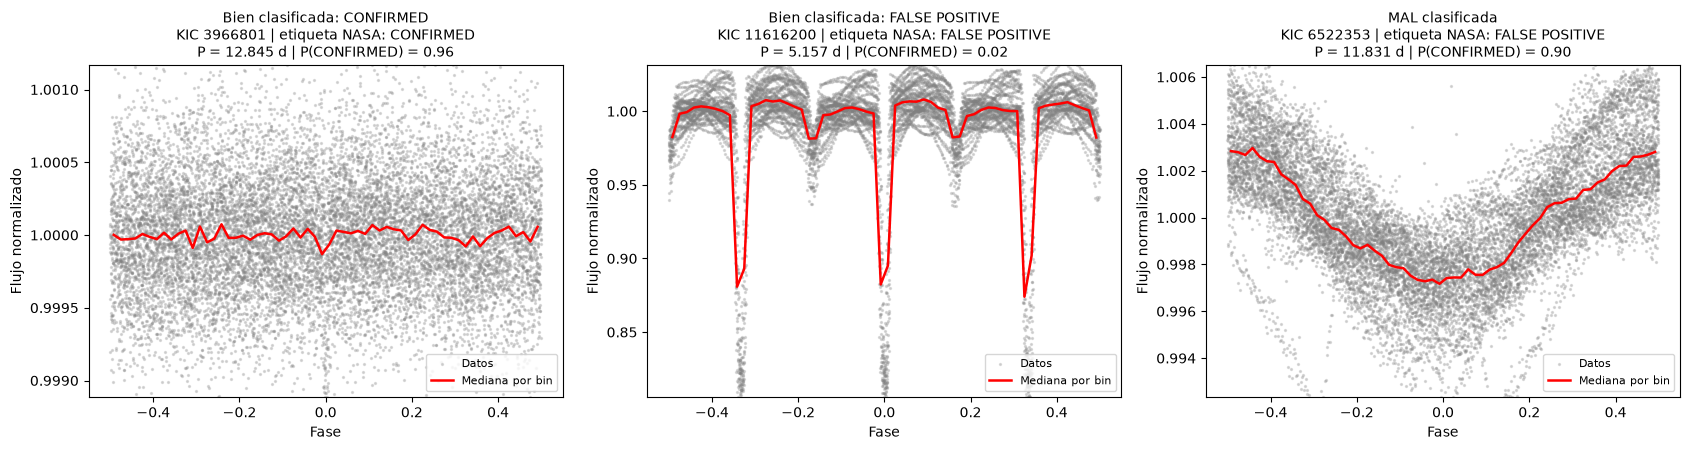

In [4]:
def analyze(k):
    """Pipeline sobre la curva cacheada + probabilidad del modelo para la estrella k."""
    lc = pd.read_csv(LC_CACHE_DIR / f"KIC_{k}_lc.csv")
    lc = normalize_flux(detrend(remove_outliers(lc, sigma=5), window_length=101))
    # Mismos parámetros que features.extract_features, para reproducir el mismo período.
    res = find_transits(lc, period_range=(0.5, 20.0), n_periods=1500,
                        n_durations=20, bls_method="fast")
    p = model.predict_proba(X[kepid == k])[0, 1]
    return lc, res, p


def binned(phase, flux, n=60):
    """Mediana del flujo en n bins de fase, para ver la forma promedio del tránsito."""
    edges = np.linspace(-0.5, 0.5, n + 1)
    idx = np.digitize(phase, edges) - 1
    centers = (edges[:-1] + edges[1:]) / 2
    med = np.array([np.median(flux[idx == i]) if (idx == i).any() else np.nan
                    for i in range(n)])
    return centers, med


fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
for ax, (title, k, truth) in zip(axes, cases):
    lc, res, p = analyze(k)
    phase = ((lc.time.values - res["t0"]) / res["period"]) % 1.0
    phase[phase > 0.5] -= 1.0
    ax.scatter(phase, lc.flux.values, s=2, alpha=0.25, c="gray", label="Datos")
    c, m = binned(phase, lc.flux.values)
    ax.plot(c, m, "r-", lw=1.8, label="Mediana por bin")
    lo, hi = np.nanpercentile(lc.flux, [0.5, 99.5])
    ax.set_ylim(lo, hi)
    ax.set_xlabel("Fase")
    ax.set_ylabel("Flujo normalizado")
    ax.set_title(f"{title}\nKIC {k} | etiqueta NASA: {truth}\n"
                 f"P = {res['period']:.3f} d | P(CONFIRMED) = {p:.2f}", fontsize=10)
    ax.legend(loc="lower right", fontsize=8)
fig.tight_layout()
plt.show()

## Cómo leer las figuras
Un tránsito planetario típico aparece como una caída pequeña, simétrica y de fondo plano, centrada en fase 0.
Pero el clasificador **no ve la imagen**: solo ve las 11 features numéricas. Por eso un error puede
significar que las features no capturaron lo que se ve en la curva, o que BLS enganchó una señal
que no es el tránsito real (ver `duration` pegada al límite de 0.3 d en más de la mitad de las estrellas).